*Pair ids renumbered by stage on 2026-10-29 (X4 → X5, X5 → X9, X6 → X8; see `bench/configs/series.yaml`). The source uses the new ids; stored outputs still show the old ones.*

# Depth, the hard pairs and where space helps

`docs/cross_species_alignment_results.md` leaves four questions about the data open ("Next steps: understanding the data and the problem"). This notebook answers them on all cross pairs (X1–X3, X5, X8, X9), seed 0 (the seed SD of κ_bal is about 0.002, section 4 of the doc):
1. **A depth-aware score.** κ_bal counts organs and can't see depth: X8, with no depth overlap, scores best of all pairs. Here, each query section's mass is followed to the target sections that receive it, and scored in laterality L.
2. **Is L comparable between the species?** If organ content does not follow L across species, a depth score in L means little.
3. **Why the early pairs are hard.** Per-organ recall on X1 and X2 against X5, X8, X9, next to how conserved each organ's expression is between the species, and a check of the stage pairing.
4. **Where space carries information.** The GW gain of 3D FGW (+0.022 on X2, +0.015 on X3), per section: does it sit at the ends of the overlap, and does it move mass to a more plausible depth? Shown on the slices.

**The runs** (names: `sides_space_features_marginals`, see the doc's "Run names"), a subset of `whole_embryo_tests.ipynb`, recomputed because that notebook keeps no couplings:
- `pts2pts_s-euc_f-euc_ub`: 3D FGW, the benchmark pipeline;
- `pts2pts_s-none_f-euc_ub`: the same solve without the GW term;
- `sec2emb_s-none_f-cos_semi0.7`: the whole-embryo match (the best run so far);
- `sec2emb_s-none_f-cos_nn`: the same with no constraint on the target;
- `sec2emb_s-none_f-lab_nn`: organ labels as the cost, the ceiling.

Their κ_bal and gene r must equal the cached scores of `whole_embryo_tests.ipynb` (checked in section 0).

**Laterality L** (`laterality/laterality_scores.csv`, `L_pair`) is derived from the organ classes of a section (axial, juxta-axial, paramedian, lateral). Like the labels, it may score an alignment but must not steer one.

**Before the first run:** the pair features must exist (`python -m mgw.bench prepare --tier full --pairs X1,X2,X3,X5,X8,X9 --seeds 0`); the stacks are cached from `whole_embryo_tests.ipynb`. Results are cached per pair and seed in `<root>/diag/depth_organs/`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIRS = ("X1", "X2", "X3", "X5", "X8", "X9")  # cross pairs of bench/configs/series.yaml (a = human, b = mouse)
SEEDS = (0,)                     # one seed: the seed SD of kappa_bal is about 0.002 (doc, section 4)
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
PIPELINE = "pts2pts_s-euc_f-euc_ub"  # the 3D pipeline whose stacks, point clouds and settings are used
INNER_TOL = 1e-5                 # Sinkhorn threshold, as in whole_embryo_tests.ipynb
TAU_B = 0.7                      # target-side relaxation of the whole-embryo match
MIN_SPOTS = 20                   # an organ needs >= MIN_SPOTS spots (majority label) for a per-organ score
N_STAGE_GENES = 2000             # genes of the stage-match matrix (most variable across organ profiles)
SLICE_PAIRS = ("X2", "X3", "X5") # pairs drawn on the slices in section 4 (mouse inside human, and a contrast)
FORCE = False                    # recompute (pair, seed) results that are cached

In [3]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from mgw import crossspecies as cs
from mgw import orthologs
from mgw.bench import config, metrics, prepare, series, solvers, volume
from mgw.bench.pipelines import volume as volume_pipeline
from mgw.bench.pipelines.common import Task

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
ser = series.load(cfg.series_path())
missing = [(pid, s) for pid in PAIRS for s in SEEDS
           if not prepare.feature_file(root, pid, s, cfg.feature_hash()).exists()]
if missing:
    pids, seeds = sorted({p for p, _ in missing}), sorted({s for _, s in missing})
    raise FileNotFoundError(f"no features for {missing}; run first: python -m mgw.bench prepare --tier full "
                            f"--pairs {','.join(pids)} --seeds {','.join(map(str, seeds))}")
OUT = root / "diag" / "depth_organs"
OUT.mkdir(parents=True, exist_ok=True)
WHOLE = root / "diag" / "whole_embryo"   # the cached scores of whole_embryo_tests.ipynb, for the check
# the cache key: every setting that changes the tables of a (pair, seed)
RUN_KEY = config.short_hash(dict(pipeline=cfg.pipeline_hash(PIPELINE), inner_tol=INNER_TOL, tau_b=TAU_B,
                                 min_spots=MIN_SPOTS))
SH = cfg.section_hash()
MIN_BINS = cfg.raw["metrics"]["present_min_bins"]
print(f"root {root}\npairs {PAIRS}, seeds {SEEDS}; results cached in {OUT}")

root /nas/lnt/ga79jin/MGW/data/bench
pairs ('X1', 'X2', 'X3', 'X4', 'X5', 'X6'), seeds (0,); results cached in /nas/lnt/ga79jin/MGW/data/bench/diag/depth_organs


## Helpers

The solver helpers are those of `whole_embryo_tests.ipynb` (`label_cost`, `ot`, `softmax_nn`, `cost_scale`, `load`, `solve_pc_fgw`). New is `describe`, which keeps four things of each coupling Pq of a query section:
- **the scores:** κ_bal (`task.score`) and gene r, computed exactly as `cs.coexpression` does (the same shuffle);
- **the mass per target section:** the column sums of Pq, summed per target section (whole embryo: the spots of each section; 3D: the stack points of each section);
- **per query organ o:** the mass of o and the part of it that lands on o, from `metrics.confusion`, on the K organs that κ_bal scores. The recall m_o is the second over the first, and κ_bal = (mean m_o − 1/K) / (1 − 1/K). Also the gene r on the query spots of organ o only (at least `MIN_SPOTS`);
- **the transferred organ** of every query spot (`metrics.hard_prediction`), for the slices.

In [4]:
f_cfg = cfg.raw["features"]


def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot(M, p, a=None, b=None, tau_a=1.0, tau_b=1.0, epsilon=None):
    """Entropic OT on the cross cost alone: masses a, b (default uniform), unbalanced for tau < 1. (P float32, info)"""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=epsilon or p.epsilon)
    a, b = (None if x is None else jnp.asarray(x / np.sum(x), dtype=jnp.float32) for x in (a, b))
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, a=a, b=b, tau_a=tau_a, tau_b=tau_b))
    return np.asarray(out.matrix, dtype=np.float32), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


def softmax_nn(M, eps):
    """tau_b -> 0: each query spot spreads its mass over the target by exp(-M / eps); the target marginal is free."""
    L = -np.asarray(M, dtype=np.float32) / eps
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True) / len(P)


def cost_scale(Fa, Fb, metric, seed):
    """The benchmark's cost scale (solvers.cost_scale: a quantile of the a x b distances), for any metric."""
    if metric == "euclidean":
        return solvers.cost_scale(Fa, Fb, f_cfg["m_scale_quantile"], f_cfg["m_scale_max_entries"], seed=seed)
    n_cols = max(1, min(len(Fb), f_cfg["m_scale_max_entries"] // max(len(Fa), 1)))
    if n_cols < len(Fb):
        Fb = Fb[np.random.default_rng(seed).choice(len(Fb), n_cols, replace=False)]
    return float(np.quantile(cdist(Fa, Fb, metric), f_cfg["m_scale_quantile"]))


def load(pid, seed):
    """A pair's task (data, cost scale and settings of PIPELINE, Sinkhorn threshold INNER_TOL) and the point clouds
    of both stacks (stage 1)."""
    task = Task(cfg, PIPELINE, ser.pairs[pid], seed, root)
    task.fgw = dataclasses.replace(task.fgw, inner_tol=INNER_TOL)
    sides = {"a": volume_pipeline._side(task, "a_stack"), "b": volume_pipeline._side(task, "b_stack")}
    return dict(task=task, sides=sides, p=task.spec["params"])


def solve_pc_fgw(ctx):
    """PIPELINE's stage 2, as in pipelines/volume.py: unbalanced FGW of the two point clouds."""
    task, p = ctx["task"], ctx["p"]
    ma, mb = ctx["sides"]["a"][2], ctx["sides"]["b"][2]
    P, _, info = volume.stage2(volume.intra_cost("fgw", ma, cfg), volume.intra_cost("fgw", mb, cfg), ma["F"],
                               mb["F"], task.scale, task.fgw, a=ma["mass"], b=mb["mass"], tau=p["tau"],
                               epsilon=p["epsilon"], unbalanced_correction=p["unbalanced_correction"])
    return P, info

In [5]:
def describe(task, d, q, tname, T, Yt, Pq, col_section, n_sections):
    """What this notebook keeps of one coupling Pq (rows: the spots of query section q; columns: target spots or
    points with compositions T, held-out genes Yt and target section index col_section).
    Returns (scores, mass share per target section, per-organ rows, transferred organ per query spot)."""
    P = np.asarray(Pq)
    kb = task.score(d, q, tname, T, P, keep=False)["kappa_bal"]
    # gene r exactly as cs.coexpression (the same shuffle), with the transported genes kept for the organ subsets
    rowsum = P.sum(1, keepdims=True) + 1e-30
    perm = np.random.default_rng(task.seed).permutation(len(Yt))
    Yh, Yh0 = (P @ Yt) / rowsum, (P @ Yt[perm]) / rowsum
    gene_r = np.nanmean(cs.colwise_r(q.Y, Yh)) - np.nanmean(cs.colwise_r(q.Y, Yh0))
    # mass per target section
    col = np.asarray(P.sum(0), dtype=np.float64).ravel()
    assert len(col_section) == len(col), "one target section per column"
    w = np.bincount(col_section, weights=col, minlength=n_sections)
    # per query organ, on the K organs kappa_bal scores
    C = metrics.confusion(P, q.comp, T)
    pt = task.target_presence(d)
    pt = metrics.present(T, MIN_BINS) if pt is None else pt
    shared = np.flatnonzero(metrics.present(q.comp, MIN_BINS) & pt)
    lab = metrics.organ_codes(q.label)
    organs = []
    for o in shared:
        m = lab == o
        r_o = (np.nanmean(cs.colwise_r(q.Y[m], Yh[m])) - np.nanmean(cs.colwise_r(q.Y[m], Yh0[m]))
               if m.sum() >= MIN_SPOTS else np.nan)
        organs.append(dict(organ=metrics.ORGANS[o], row=C[o, shared].sum(), same=C[o, o],
                           n_bins=q.comp[:, o].sum(), n_spots=int(m.sum()), gene_r=r_o, K=len(shared)))
    pred = metrics.hard_prediction(P, T).astype(np.uint8)
    return dict(kappa_bal=kb, gene_r=gene_r, mass=float(col.sum())), w / max(w.sum(), 1e-300), organs, pred

## 0. The couplings, per pair and seed

The five runs, each query section in both directions. Each (pair, seed) writes four files to `OUT`:
- `rows`: one row per (run, direction, query section), with κ_bal, gene r, the query's L, its position in its own stack and the target's L range;
- `mass`: the share of the query's mass on each target section;
- `organs`: the per-organ rows;
- `transfer.npz`: the transferred organ per query spot.

Directions: `b_stack` has the human sections as queries (human → mouse), `a_stack` the mouse sections (mouse → human).

In [6]:
PTS_FGW, PTS_W, LABEL = PIPELINE, "pts2pts_s-none_f-euc_ub", "sec2emb_s-none_f-lab_nn"
REF, NN = f"sec2emb_s-none_f-cos_semi{TAU_B:g}", "sec2emb_s-none_f-cos_nn"
RUN_ORDER = [PTS_FGW, PTS_W, REF, NN, LABEL]
WHOLE_RUNS = [(REF, TAU_B, "features"), (NN, 0.0, "features"), (LABEL, 0.0, "labels")]
DIR = {"b_stack": "human → mouse", "a_stack": "mouse → human"}


def run_one(pid, seed):
    """Every run of one pair and seed: the four tables of section 0."""
    t0 = time.perf_counter()
    ctx = load(pid, seed)
    task, p, sides = ctx["task"], ctx["p"], ctx["sides"]
    ma, mb = sides["a"][2], sides["b"][2]
    print(f"  {pid} seed {seed} stage 1: {time.perf_counter() - t0:.0f} s ({len(ma['F'])} x {len(mb['F'])} points)")
    stack_pos = {n: (i, len(ST["names"])) for side in "ab" for ST in [sides[side][1]] for i, n in enumerate(ST["names"])}
    rows, mass, organs, pred = [], [], [], {}

    def keep(run, kind, d, q, tname, T, Yt, Pq, col_section, tsecs):
        s, w, org, pr = describe(task, d, q, tname, T, Yt, Pq, col_section, len(tsecs))
        Lt = np.array([t.L for t in tsecs])
        pos, n_stack = stack_pos.get(q.name, (np.nan, np.nan))
        rows.append(dict(run=run, kind=kind, direction=d, query=q.name, L_q=q.L, stack_pos=pos, stack_n=n_stack,
                         t_Lmin=np.nanmin(Lt), t_Lmax=np.nanmax(Lt), **s))
        mass.extend(dict(run=run, direction=d, query=q.name, L_q=q.L, target_section=t.name, L_t=t.L,
                         n_bins_t=t.comp.sum(), share=wt) for t, wt in zip(tsecs, w))
        organs.extend(dict(run=run, direction=d, query=q.name, **o) for o in org)
        pred[f"{run}|{d}|{q.name}"] = pr

    # 3D: the benchmark's FGW and the same solve without the GW term, mapped back to the spots as in pipelines/volume.py
    t0 = time.perf_counter()
    P, _ = solve_pc_fgw(ctx)
    P_w, _ = ot(task.cross_cost(ma["F"], mb["F"]), task.fgw, ma["mass"], mb["mass"], p["tau"], p["tau"], p["epsilon"])
    for run, Pab in ((PTS_FGW, P), (PTS_W, P_w)):
        for d, Pd in (("b_stack", Pab), ("a_stack", Pab.T)):
            (_, STq, mq), (_, STt, mt) = (sides["a"], sides["b"]) if d == "b_stack" else (sides["b"], sides["a"])
            qs, ts = task.sides(d)
            B = volume.target_pool(mt, STt, p["k_target"])
            T, Yt = (np.asarray(B @ STt[k]) for k in ("comp", "Y"))
            tsecs = [ts[n] for n in STt["names"]]           # mt["section"] indexes STt["names"]
            for s, name in enumerate(STq["names"]):
                Pq = np.asarray(volume.query_map(mq, STq, s, p["k_query"]) @ Pd)
                keep(run, "3D points", d, qs[name], "points", T, Yt, Pq, mt["section"], tsecs)
                del Pq
    del P, P_w
    print(f"  {pid} seed {seed} 3D runs: {time.perf_counter() - t0:.0f} s")
    # the whole embryo as target, cosine features (and the label ceiling)
    t0 = time.perf_counter()
    Fa, Fb = (np.vstack([s.emb for s in task.data[side].values()]) for side in ("a", "b"))
    scale = cost_scale(Fa, Fb, "cosine", seed)
    for d in ("b_stack", "a_stack"):
        qs, ts = task.sides(d)
        tsecs = list(ts.values())
        tname = f"{task.target_embryo(d).name} (all sections)"
        T, Yt = np.vstack([s.comp for s in tsecs]), np.vstack([s.Y for s in tsecs])
        Ft = np.vstack([s.emb for s in tsecs])
        col_section = np.repeat(np.arange(len(tsecs)), [s.n for s in tsecs])
        for q in qs.values():
            M = (cdist(q.emb, Ft, "cosine") / scale).astype(np.float32)
            for run, tb, cost in WHOLE_RUNS:
                Cm = label_cost(q.comp, T).astype(np.float32) if cost == "labels" else M
                Pq = softmax_nn(Cm, task.fgw.epsilon) if tb == 0 else ot(Cm, task.fgw, tau_b=tb)[0]
                keep(run, "whole embryo", d, q, tname, T, Yt, Pq, col_section, tsecs)
                del Pq, Cm
    print(f"  {pid} seed {seed} whole embryo: {time.perf_counter() - t0:.0f} s")
    tag = dict(pair=pid, seed=seed)
    return (pd.DataFrame(rows).assign(**tag), pd.DataFrame(mass).assign(**tag), pd.DataFrame(organs).assign(**tag),
            pred)

In [7]:
def files(pid, seed):
    stem = OUT / f"{pid}_seed{seed}_{RUN_KEY}"
    return {k: stem.with_name(f"{stem.name}_{k}.csv") for k in ("rows", "mass", "organs")} | {
        "transfer": stem.with_name(f"{stem.name}_transfer.npz")}


tables = {"rows": [], "mass": [], "organs": []}
for pid in PAIRS:
    for seed in SEEDS:
        f = files(pid, seed)
        if all(x.exists() for x in f.values()) and not FORCE:
            for k in tables:
                tables[k].append(pd.read_csv(f[k]))
            print(f"{pid} seed {seed}: cached")
            continue
        t0 = time.perf_counter()
        rows, mass, organs, pred = run_one(pid, seed)
        for k, df in (("rows", rows), ("mass", mass), ("organs", organs)):
            df.to_csv(f[k], index=False)
            tables[k].append(df)
        prepare.atomic_savez(f["transfer"], **pred)
        print(f"{pid} seed {seed}: {len(rows)} couplings, {(time.perf_counter() - t0) / 60:.0f} min")
rows, mass, organs = (pd.concat(tables[k], ignore_index=True) for k in ("rows", "mass", "organs"))
KEY = ["pair", "seed", "run", "direction", "query"]

  CS12-13_E2: 6000 points points, spacing 0.0174


  E9.5_E2: 5998 points points, spacing 0.0336
  X1 seed 0 stage 1: 6 s (6000 x 5998 points)


  X1 seed 0 3D runs: 23 s


  X1 seed 0 whole embryo: 51 s
X1 seed 0: 60 couplings, 1 min


  CS14-15_E2: 5999 points points, spacing 0.0188


...

  X5 seed 0 whole embryo: 66 s
X5 seed 0: 65 couplings, 1 min


  CS20_E2: 6000 points points, spacing 0.0225


  E13.5_E1: 5999 points points, spacing 0.0264
  X6 seed 0 stage 1: 2 s (6000 x 5999 points)


  X6 seed 0 3D runs: 24 s


  X6 seed 0 whole embryo: 28 s
X6 seed 0: 40 couplings, 1 min


**Checks.**
- κ_bal and gene r equal the cached scores of `whole_embryo_tests.ipynb` (same seed, same `INNER_TOL`), where they exist.
- The mass shares of each coupling sum to 1.
- The per-organ rows give back κ_bal.

In [8]:
TOL = 1e-3
chk = []
for pid in PAIRS:
    for seed in SEEDS:
        # every cached file of this pair and seed (earlier rounds too); the one sharing the most rows is the reference
        best = None
        for f in WHOLE.glob(f"{pid}_seed{seed}_*.csv"):
            c = pd.read_csv(f)
            if not {"run", "direction", "query", "kappa_bal", "gene_r"} <= set(c.columns):
                continue
            m = rows[(rows.pair == pid) & (rows.seed == seed)].merge(
                c[["run", "direction", "query", "kappa_bal", "gene_r"]], on=["run", "direction", "query"],
                suffixes=("", "_cached"))
            if len(m) and (best is None or len(m) > len(best[1])):
                best = (f, m)
        if best is None:
            continue
        f, m = best
        chk.append(dict(pair=pid, seed=seed, file=f.name, n=len(m),
                        max_dk=(m.kappa_bal - m.kappa_bal_cached).abs().max(),
                        max_dr=(m.gene_r - m.gene_r_cached).abs().max()))
if chk:
    chk = pd.DataFrame(chk)
    print(f"against whole_embryo_tests.ipynb (largest |difference| per pair)\n{chk.round(6).to_string(index=False)}")
    assert (chk[["max_dk", "max_dr"]].fillna(0) < TOL).all().all(), \
        "the recomputed scores differ from whole_embryo_tests.ipynb"
else:
    print(f"no matching cached scores of whole_embryo_tests.ipynb in {WHOLE}: check skipped")

tot = mass.groupby(KEY).share.sum()
assert np.allclose(tot, 1, atol=1e-6), f"mass shares do not sum to 1: {tot.min():.6f}..{tot.max():.6f}"

o = organs.assign(m=np.where(organs.row > 0, organs.same / organs.row.where(organs.row > 0, 1), 0.0))
kb = o.groupby(KEY).apply(lambda g: (g.m.mean() - 1 / g.K.iloc[0]) / (1 - 1 / g.K.iloc[0]) if g.K.iloc[0] >= 2
                          else np.nan, include_groups=False)
kb = rows.set_index(KEY).kappa_bal.to_frame().join(kb.rename("from_organs"))
assert np.allclose(kb.kappa_bal, kb.from_organs, atol=1e-8, equal_nan=True), "per-organ rows do not give kappa_bal"
print(f"\n{len(rows)} couplings; mass shares sum to 1; the per-organ rows give back kappa_bal")

against whole_embryo_tests.ipynb (largest |difference| per pair)
pair  seed                  file  n   max_dk   max_dr
  X1     0 X1_seed0_df26486b.csv 60 0.000002 0.000000
  X2     0 X2_seed0_df26486b.csv 65 0.000005 0.000001
  X3     0 X3_seed0_df26486b.csv 70 0.000005 0.000001
  X4     0 X4_seed0_df26486b.csv 55 0.000001 0.000003
  X5     0 X5_seed0_df26486b.csv 65 0.000002 0.000003
  X6     0 X6_seed0_df26486b.csv 40 0.000002 0.000004

355 couplings; mass shares sum to 1; the per-organ rows give back kappa_bal


## 1. A depth-aware score

Per query section, with w_t the share of its mass on target section t and L_q its own laterality:
- **L̄** = Σ_t w_t L_t: where in depth the mass goes.
- **dL** = Σ_t w_t |L_t − L_q|: the depth error. **dL_min** = min_t |L_t − L_q|: all mass on the target section with the closest L. **dL_chance**: the mass spread like the target embryo's tissue (bins per section).
- **near share**: the share of the mass on that closest section.
- **depth skill** = (dL_chance − dL) / (dL_chance − dL_min). 0 is chance, 1 is the closest section, < 0 worse than chance. Pooled per (pair, direction, run) as Σ numerator / Σ denominator, so that sections whose closest target is barely better than chance (a thin target range, as X3's mouse) don't dominate.
- **depth order ρ**: the Spearman correlation between L_q and L̄ over the query sections of one (pair, direction, run). It asks only whether the order of the sections is kept, so a scale mismatch of L between the species doesn't matter.

Target sections without L are left out (their mass with them).

In [9]:
def depth_table(mass):
    """One row per coupling: L_bar, dL, dL_min, dL_chance, near share."""
    out = []
    for k, g in mass[np.isfinite(mass.L_t)].groupby(KEY):
        w = g.share.to_numpy() / g.share.sum()
        Lt, Lq = g.L_t.to_numpy(), g.L_q.iloc[0]
        c = g.n_bins_t.to_numpy() / g.n_bins_t.sum()
        dist = np.abs(Lt - Lq)
        out.append(dict(zip(KEY, k), L_q=Lq, L_bar=w @ Lt, L_chance=c @ Lt, dL=w @ dist, dL_min=dist.min(),
                        dL_chance=c @ dist, near_share=w[dist == dist.min()].sum()))
    return pd.DataFrame(out)


def pooled(g):
    num, den = (g.dL_chance - g.dL).sum(), (g.dL_chance - g.dL_min).sum()
    ok = np.isfinite(g.L_q)
    rho = spearmanr(g.L_q[ok], g.L_bar[ok]).statistic if ok.sum() >= 3 and g.L_q[ok].nunique() > 1 else np.nan
    return pd.Series(dict(skill=num / den if den > 1e-9 else np.nan, rho=rho, dL=g.dL.mean(),
                          dL_min=g.dL_min.mean(), dL_chance=g.dL_chance.mean(), near_share=g.near_share.mean(),
                          n=len(g)))


depth = depth_table(mass)
depth_p = depth.groupby(["pair", "seed", "run", "direction"]).apply(pooled, include_groups=False).reset_index()
assert depth_p[depth_p.run == LABEL].skill.notna().all(), "the label ceiling has no depth skill on some pair"


def by_pair_dir(col):
    t = depth_p.pivot_table(index="run", columns=["direction", "pair"], values=col).reindex(RUN_ORDER)
    t = t.reindex(columns=[(d, p) for d in DIR for p in PAIRS if (d, p) in t.columns])
    t.columns = [f"{p} {DIR[d].split()[0][0].upper()}→" for d, p in t.columns]   # e.g. "X1 H→": human queries
    return t


print("depth skill (0 = chance, 1 = all mass on the closest target section; H→: human queries, M→: mouse queries)")
print(by_pair_dir("skill").round(2).to_string())
print("\ndepth order rho (Spearman of L_q and L_bar over the query sections)")
print(by_pair_dir("rho").round(2).to_string())
print("\nnear share (mass on the target section with the closest L)")
print(by_pair_dir("near_share").round(2).to_string())
print("\nmean dL against dL_min (closest section) and dL_chance, per run (mean over pairs and directions)")
print(depth_p.groupby("run")[["dL", "dL_min", "dL_chance", "skill", "rho"]].mean().reindex(RUN_ORDER).round(3)
      .to_string())

depth skill (0 = chance, 1 = all mass on the closest target section; H→: human queries, M→: mouse queries)
                              X1 H→  X2 H→  X3 H→  X4 H→  X5 H→  X6 H→  X1 M→  X2 M→  X3 M→  X4 M→  X5 M→  X6 M→
run                                                                                                             
pts2pts_s-euc_f-euc_ub        -0.13   0.06  -0.04   0.04   0.20   0.02   0.04  -0.05   0.19   0.03   0.09   0.02
pts2pts_s-none_f-euc_ub       -0.13   0.06  -0.04   0.02   0.20   0.03   0.04  -0.04   0.19   0.01   0.09   0.02
sec2emb_s-none_f-cos_semi0.7  -0.04   0.01   0.02   0.07   0.08   0.03   0.05   0.23   0.06   0.08   0.06   0.13
sec2emb_s-none_f-cos_nn       -0.05   0.03   0.02   0.05   0.08   0.08   0.08   0.34   0.08   0.11   0.09   0.12
sec2emb_s-none_f-lab_nn        0.09   0.03   0.02   0.05   0.01   0.11   0.06   0.10  -0.15   0.01   0.03   0.16

depth order rho (Spearman of L_q and L_bar over the query sections)
                              X1 

**The X8 check.** X8 has no depth overlap (human L 0.27–0.76, mouse 0.04–0.21). A plausible placement sends the human sections to the most lateral mouse sections, and the mouse sections to the most medial human ones. The table gives the share of the mass on that end section per run.

In [10]:
if "X8" in PAIRS:
    m6 = mass[(mass.pair == "X8") & np.isfinite(mass.L_t)].copy()
    end = {"b_stack": m6[m6.direction == "b_stack"].L_t.max(),    # human queries: the most lateral mouse section
           "a_stack": m6[m6.direction == "a_stack"].L_t.min()}    # mouse queries: the most medial human section
    m6["at_end"] = m6.L_t == m6.direction.map(end)
    t = (m6[m6.at_end].groupby(["run", "direction"]).share.sum() / m6.groupby(["run", "direction"])["query"].nunique()
         ).unstack("direction").reindex(RUN_ORDER).rename(columns=DIR)
    chance = (m6[m6.at_end].groupby("direction").n_bins_t.first()
              / m6.drop_duplicates(["direction", "target_section"]).groupby("direction").n_bins_t.sum()).rename(DIR)
    print(f"X8: share of the mass on the end section (mouse L {end['b_stack']:.2f}, human L {end['a_stack']:.2f})")
    print(t.round(2).to_string())
    print(f"\nchance (the end section's share of the tissue): " + ", ".join(f"{k} {v:.2f}" for k, v in chance.items()))

X6: share of the mass on the end section (mouse L 0.21, human L 0.27)
direction                     mouse → human  human → mouse
run                                                       
pts2pts_s-euc_f-euc_ub                 0.16           0.21
pts2pts_s-none_f-euc_ub                0.17           0.21
sec2emb_s-none_f-cos_semi0.7           0.25           0.22
sec2emb_s-none_f-cos_nn                0.24           0.21
sec2emb_s-none_f-lab_nn                0.36           0.29

chance (the end section's share of the tissue): mouse → human 0.22, human → mouse 0.25


### Figure: where in depth the mass goes

One panel per pair and direction. x: the query section's L, y: L̄, the mass-weighted L of the target sections that receive its mass. The shaded band is the target's L range, and the dotted line is chance (the target's tissue-weighted mean L). The thin step line is the L of the closest target section, where a perfect depth placement would put each point. Three runs: 3D FGW, the whole-embryo match and the label ceiling.

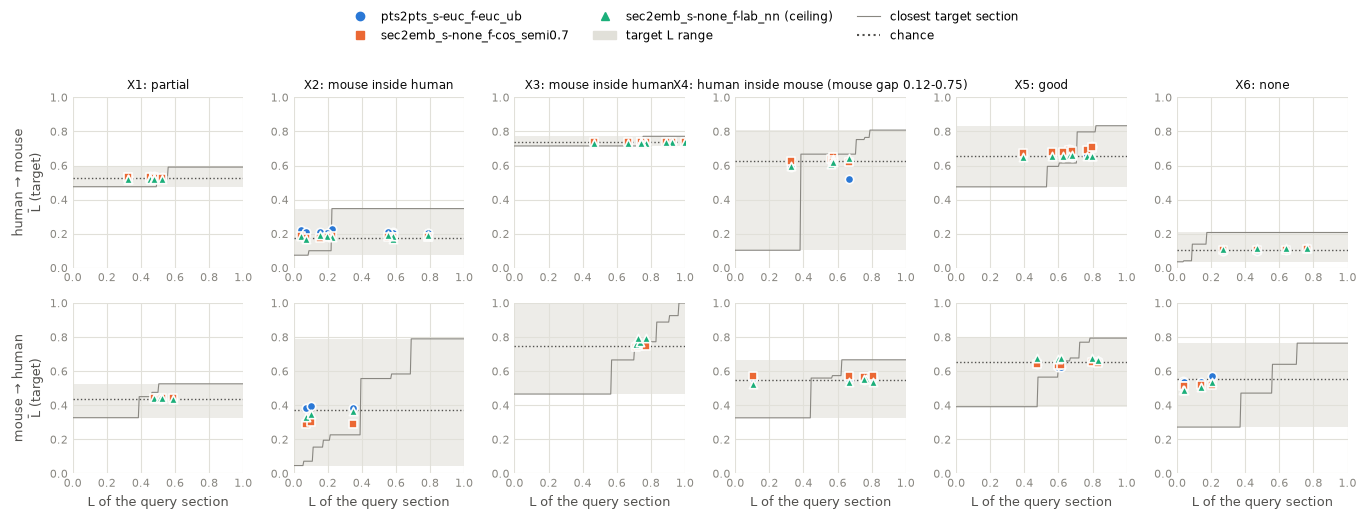

In [11]:
INK, SECOND, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOT = ["#2a78d6", "#eb6834", "#1baf7a"]          # categorical slots 1-3: they validate all-pairs (scatter)
DEPTH_RUNS = {PTS_FGW: SLOT[0], REF: SLOT[1], LABEL: SLOT[2]}
MARK = {PTS_FGW: "o", REF: "s", LABEL: "^"}


def clean(ax):
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)


seed0 = SEEDS[0]
fig, axes = plt.subplots(2, len(PAIRS), figsize=(2.3 * len(PAIRS), 5.2), squeeze=False)
for i, d in enumerate(DIR):
    for j, pid in enumerate(PAIRS):
        ax = axes[i, j]
        g = depth[(depth.pair == pid) & (depth.seed == seed0) & (depth.direction == d)]
        tL = mass[(mass.pair == pid) & (mass.seed == seed0) & (mass.direction == d)].drop_duplicates(
            "target_section").L_t.dropna().sort_values().to_numpy()
        if len(tL):
            ax.axhspan(tL.min(), tL.max(), color=GRID, alpha=0.6, lw=0)
            x = np.linspace(0, 1, 201)
            ax.plot(x, tL[np.abs(x[:, None] - tL[None]).argmin(1)], color=MUTED, lw=0.8)
        if len(g):
            ax.axhline(g.L_chance.iloc[0], color=SECOND, ls=":", lw=1)
        for run, color in DEPTH_RUNS.items():
            h = g[g.run == run]
            ax.scatter(h.L_q, h.L_bar, s=36, color=color, marker=MARK[run], edgecolors=SURFACE, linewidths=1.2,
                       zorder=3)
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect("equal")
        clean(ax)
        if i == 0:
            ax.set_title(f"{pid}: {ser.pairs[pid].overlap}", fontsize=8.5, color=INK)
        if j == 0:
            ax.set_ylabel(f"{DIR[d]}\nL̄ (target)", fontsize=9, color=SECOND)
        if i == 1:
            ax.set_xlabel("L of the query section", fontsize=9, color=SECOND)
handles = [Line2D([], [], marker=MARK[r], ls="", color=c, label=r + (" (ceiling)" if r == LABEL else ""))
           for r, c in DEPTH_RUNS.items()]
handles += [Patch(color=GRID, label="target L range"), Line2D([], [], color=MUTED, lw=0.8, label="closest target section"),
            Line2D([], [], color=SECOND, ls=":", label="chance")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
plt.show()

## 2. Is L comparable between the species?

Two label-based checks; neither uses an alignment method.
- **Composition against ΔL.** For every human × mouse section pair: the cosine similarity of their organ compositions (the scored organs' share of the bins) against |L_human − L_mouse|. If L means the same in both species, sections at similar L should hold similar organs, so ρ < 0.
- **The ceiling's placement.** `sec2emb_s-none_f-lab_nn` matches each spot to spots of its own organ. Its depth skill and ρ (section 1) show whether perfect labels place sections in L. If they don't, the features can't be blamed for ignoring L.

organ composition similarity against |L_human - L_mouse| (rho < 0: closer in L, more alike)
           rho   n   dL_range
pair                         
X1   -0.062638  32  0.00-0.26
X2   -0.670748  30  0.00-0.72
X3   -0.252256  40  0.00-0.31
X4   -0.525977  30  0.00-0.56
X5   -0.118696  40  0.00-0.44
X6   -0.332353  16  0.06-0.73
pooled rho -0.23 over 188 section pairs

the label ceiling's depth placement (section 1)
                    rho                       skill              
direction human → mouse mouse → human human → mouse mouse → human
pair                                                             
X1                -0.48          -0.4          0.09          0.06
X2                 0.26           1.0          0.03          0.10
X3                 0.66           0.4          0.02         -0.15
X4                 0.94           0.6          0.05          0.01
X5                 0.30          -0.3          0.01          0.03
X6                 0.80           0.8          0.11

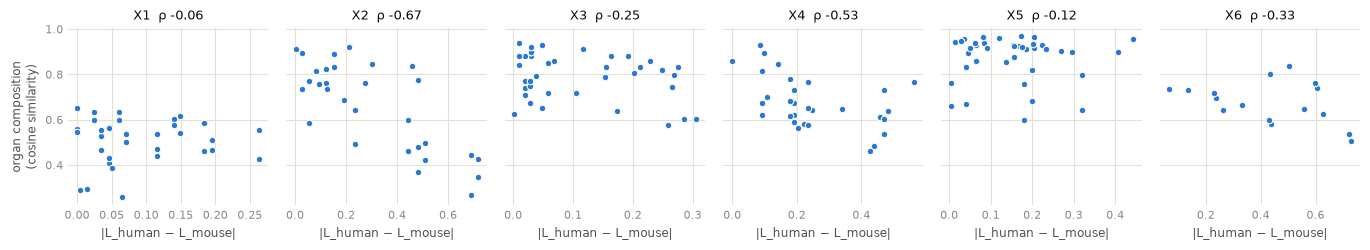

In [12]:
comp_rows = []
for pid in PAIRS:
    pair = ser.pairs[pid]
    secs = {side: [prepare.load_section(root, s, seed0, SH) for s in e.sections] for side, e in (("a", pair.a), ("b", pair.b))}
    for h in secs["a"]:
        ch = metrics.row_normalize(h.comp[:, metrics.SCORED].sum(0, keepdims=True))[0]
        for m in secs["b"]:
            cm = metrics.row_normalize(m.comp[:, metrics.SCORED].sum(0, keepdims=True))[0]
            comp_rows.append(dict(pair=pid, human=h.name, mouse=m.name, dL=abs(h.L - m.L),
                                  similarity=ch @ cm / (np.linalg.norm(ch) * np.linalg.norm(cm) + 1e-30)))
comp_sim = pd.DataFrame(comp_rows).dropna(subset=["dL"])


def rho(g):
    return spearmanr(g.dL, g.similarity).statistic if len(g) >= 3 else np.nan


t = comp_sim.groupby("pair").apply(lambda g: pd.Series(dict(rho=rho(g), n=len(g), dL_range=f"{g.dL.min():.2f}-{g.dL.max():.2f}")),
                                   include_groups=False).reindex(list(PAIRS))
print("organ composition similarity against |L_human - L_mouse| (rho < 0: closer in L, more alike)")
print(t.to_string())
print(f"pooled rho {rho(comp_sim):.2f} over {len(comp_sim)} section pairs")
print("\nthe label ceiling's depth placement (section 1)")
print(depth_p[depth_p.run == LABEL].assign(direction=lambda x: x.direction.map(DIR))
      .pivot_table(index="pair", columns="direction", values=["skill", "rho"]).reindex(list(PAIRS)).round(2).to_string())

fig, axes = plt.subplots(1, len(PAIRS), figsize=(2.3 * len(PAIRS), 2.6), sharey=True, squeeze=False)
for ax, pid in zip(axes[0], PAIRS):
    g = comp_sim[comp_sim.pair == pid]
    ax.scatter(g.dL, g.similarity, s=22, color=SLOT[0], edgecolors=SURFACE, linewidths=0.8)
    ax.set_title(f"{pid}  ρ {rho(g):+.2f}", fontsize=9, color=INK)
    ax.set_xlabel("|L_human − L_mouse|", fontsize=8.5, color=SECOND)
    clean(ax)
axes[0, 0].set_ylabel("organ composition\n(cosine similarity)", fontsize=8.5, color=SECOND)
fig.tight_layout()
plt.show()

## 3. Why the early pairs are hard

### Per-organ recall

m_o, the share of query organ o's mass that lands on o, pooled over the query sections of both directions. The heatmaps show the whole-embryo match and 3D FGW, one column per pair. The table gives each pair's mean recall and K: κ_bal rescales the mean recall by the chance level 1/K, so a pair with fewer organs needs a higher recall for the same κ_bal.

per pair: organs scored, mean K per section, mean recall over organs, kappa_bal and gene r
                          K                                                                      gene_r                                                                   kappa_bal                                                                 mean_recall                                                     
run  pts2pts_s-euc_f-euc_ub sec2emb_s-none_f-cos_semi0.7 sec2emb_s-none_f-lab_nn pts2pts_s-euc_f-euc_ub sec2emb_s-none_f-cos_semi0.7 sec2emb_s-none_f-lab_nn pts2pts_s-euc_f-euc_ub sec2emb_s-none_f-cos_semi0.7 sec2emb_s-none_f-lab_nn pts2pts_s-euc_f-euc_ub sec2emb_s-none_f-cos_semi0.7 sec2emb_s-none_f-lab_nn
pair                                                                                                                                                                                                                                                                                               

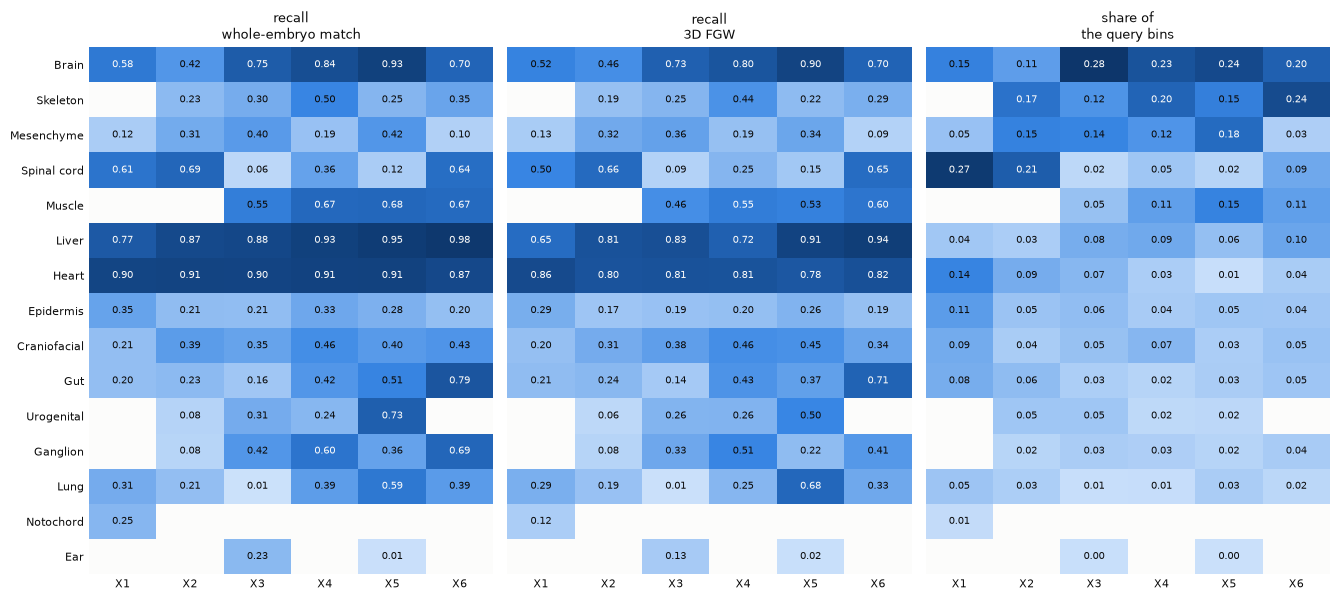

In [13]:
def recall(df, by):
    g = df.groupby(by)[["same", "row", "n_bins"]].sum()
    return g.assign(recall=g.same / g.row.where(g.row > 0))


rec = recall(organs, ["pair", "seed", "run", "organ"]).reset_index()
summary = []
for pid in PAIRS:
    for run in (REF, PTS_FGW, LABEL):
        g = rec[(rec.pair == pid) & (rec.run == run)]
        r = rows[(rows.pair == pid) & (rows.run == run)]
        k = organs[(organs.pair == pid) & (organs.run == run)].drop_duplicates(KEY).K.mean()
        summary.append(dict(pair=pid, run=run, organs=len(g), K=k,
                            mean_recall=g.recall.mean(), kappa_bal=r.kappa_bal.mean(), gene_r=r.gene_r.mean()))
print("per pair: organs scored, mean K per section, mean recall over organs, kappa_bal and gene r")
print(pd.DataFrame(summary).pivot_table(index="pair", columns="run", values=["mean_recall", "K", "kappa_bal", "gene_r"])
      .reindex(list(PAIRS)).round(3).to_string())

SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95",
                                                 "#0d366b"])
SEQ.set_bad(SURFACE)
share = rec[rec.run == REF].pivot_table(index="organ", columns="pair", values="n_bins")
share = (share / share.sum()).reindex(columns=list(PAIRS))
order = share.mean(axis=1).sort_values(ascending=False).index
fig, axes = plt.subplots(1, 3, figsize=(3 * (0.55 * len(PAIRS) + 0.6) + 1.8, 0.3 * len(order) + 1.6), sharey=True)
for ax, (run, title, val, cmap, vmax) in zip(axes, (
        (REF, "recall\nwhole-embryo match", "recall", SEQ, 1), (PTS_FGW, "recall\n3D FGW", "recall", SEQ, 1),
        (REF, "share of\nthe query bins", None, SEQ, None))):
    t = (rec[rec.run == run].pivot_table(index="organ", columns="pair", values=val).reindex(index=order, columns=list(PAIRS))
         if val else share.reindex(order))
    vmax = vmax or np.nanmax(t.to_numpy())
    ax.imshow(np.ma.masked_invalid(t.to_numpy()), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for (y, x), v in np.ndenumerate(t.to_numpy()):
        if np.isfinite(v):
            ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=7, color=INK if v < 0.55 * vmax else SURFACE)
    ax.set_xticks(range(len(PAIRS)), PAIRS, fontsize=8, color=INK)
    ax.set_title(title, fontsize=9, color=INK)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_yticks(range(len(order)), order, fontsize=8, color=INK)
fig.tight_layout(w_pad=1)
plt.show()

### Organ conservation between the species

Per pair, from labels only:
- **Expression:** each organ's mean profile of the 500 held-out genes per species (spots weighted by their share of the organ), centred per gene over the organs present on both sides. **r_same** is the Pearson r of an organ's human and mouse profiles. **margin** is r_same minus the best r with any other organ, the mean of the human-side and the mouse-side margins. **own_best**: the organ's counterpart is its best match on both sides.
- **Features:** the same with the organ centroids of the shared embedding and cosine similarity (**f_same**, **f_margin**, **f_own_best**). This is what the alignment sees.

Organs: scored, at least `MIN_SPOTS` spots (majority label) on each side.

In [14]:
def organ_profiles(secs, X):
    """(organ profiles (organs x columns of X), spots with each majority organ) over a side's sections."""
    W = metrics.row_normalize(np.vstack([s.comp for s in secs]))
    prof = (W.T @ X) / np.where(W.sum(0) > 0, W.sum(0), 1)[:, None]
    return prof, np.bincount(np.concatenate([metrics.organ_codes(s.label) for s in secs]), minlength=len(metrics.ORGANS))


def corr_rows(A, B, kind):
    """organs x organs similarity between the rows of A and B (Pearson r of centred rows, or cosine)."""
    if kind == "pearson":
        A, B = A - A.mean(1, keepdims=True), B - B.mean(1, keepdims=True)
    A, B = A / np.linalg.norm(A, axis=1, keepdims=True), B / np.linalg.norm(B, axis=1, keepdims=True)
    return A @ B.T


def match_stats(S, prefix):
    off = S - np.diag(np.full(len(S), np.inf))
    margin = 0.5 * ((np.diag(S) - off.max(1)) + (np.diag(S) - off.max(0)))
    own = (S.argmax(1) == np.arange(len(S))) & (S.argmax(0) == np.arange(len(S)))
    return {f"{prefix}same": np.diag(S), f"{prefix}margin": margin, f"{prefix}own_best": own}


cons = []
for pid in PAIRS:
    data = prepare.load_pair(ser.pairs[pid], cfg, seed0, root)
    hs, ms = list(data["a"].values()), list(data["b"].values())
    (Yh, nh), (Ym, nm) = organ_profiles(hs, np.vstack([s.Y for s in hs])), organ_profiles(ms, np.vstack([s.Y for s in ms]))
    (Fh, _), (Fm, _) = organ_profiles(hs, np.vstack([s.emb for s in hs])), organ_profiles(ms, np.vstack([s.emb for s in ms]))
    keep_o = np.flatnonzero(metrics.SCORED & (nh >= MIN_SPOTS) & (nm >= MIN_SPOTS))
    if len(keep_o) < 2:
        continue
    Yh_c, Ym_c = (Y[keep_o] - Y[keep_o].mean(0) for Y in (Yh, Ym))          # centred per gene over the shared organs
    stats = match_stats(corr_rows(Yh_c, Ym_c, "pearson"), "") | match_stats(corr_rows(Fh[keep_o], Fm[keep_o], "cosine"), "f_")
    cons.append(pd.DataFrame(dict(pair=pid, organ=np.asarray(metrics.ORGANS)[keep_o], n_human=nh[keep_o],
                                  n_mouse=nm[keep_o], **stats)))
    del data
cons = pd.concat(cons, ignore_index=True)
rec_mean = lambda run: rec[rec.run == run].groupby(["pair", "organ"]).recall.mean()   # mean over seeds
cons = cons.merge(rec_mean(REF).reset_index(), on=["pair", "organ"], how="left").merge(
    rec_mean(PTS_FGW).rename("recall_3d").reset_index(), on=["pair", "organ"], how="left")
pair_cons = cons.groupby("pair").agg(organs=("organ", "size"), r_same=("same", "mean"), margin=("margin", "mean"),
                                     own_best=("own_best", "mean"), f_same=("f_same", "mean"),
                                     f_margin=("f_margin", "mean"), f_own_best=("f_own_best", "mean"),
                                     recall=("recall", "mean")).reindex(list(PAIRS))
print("per pair: mean organ conservation (expression, then features) and the whole-embryo match's mean recall")
print(pair_cons.round(3).to_string())
sp_r = lambda g, x: spearmanr(g[x], g.recall, nan_policy="omit").statistic if g[x].notna().sum() >= 3 else np.nan
print("\nSpearman of per-organ recall (whole-embryo match) with conservation, per pair and pooled")
t = pd.DataFrame({x: [sp_r(cons[cons.pair == p], x) for p in PAIRS] + [sp_r(cons, x)]
                  for x in ("same", "margin", "f_same", "f_margin")}, index=list(PAIRS) + ["pooled"])
print(t.round(2).to_string())

per pair: mean organ conservation (expression, then features) and the whole-embryo match's mean recall
      organs  r_same  margin  own_best  f_same  f_margin  f_own_best  recall
pair                                                                        
X1        10   0.509   0.104     0.600   0.424     0.093       0.600   0.429
X2        12   0.566   0.131     0.417   0.568     0.152       0.667   0.385
X3        14   0.637   0.146     0.714   0.583     0.098       0.643   0.395
X4        13   0.755   0.238     1.000   0.688     0.139       0.615   0.527
X5        13   0.760   0.168     0.846   0.724     0.177       0.769   0.549
X6        12   0.742   0.134     0.667   0.692     0.130       0.750   0.568

Spearman of per-organ recall (whole-embryo match) with conservation, per pair and pooled
        same  margin  f_same  f_margin
X1      0.56    0.61    0.94      0.92
X2      0.65    0.57    0.71      0.70
X3      0.87    0.82    0.48      0.58
X4      0.68    0.54    0.49      0

**Figure: recall against conservation.** One panel per pair, one point per organ. Top: expression conservation (r_same), bottom: the organ's margin in the feature space. The three organs with the lowest recall are labelled.

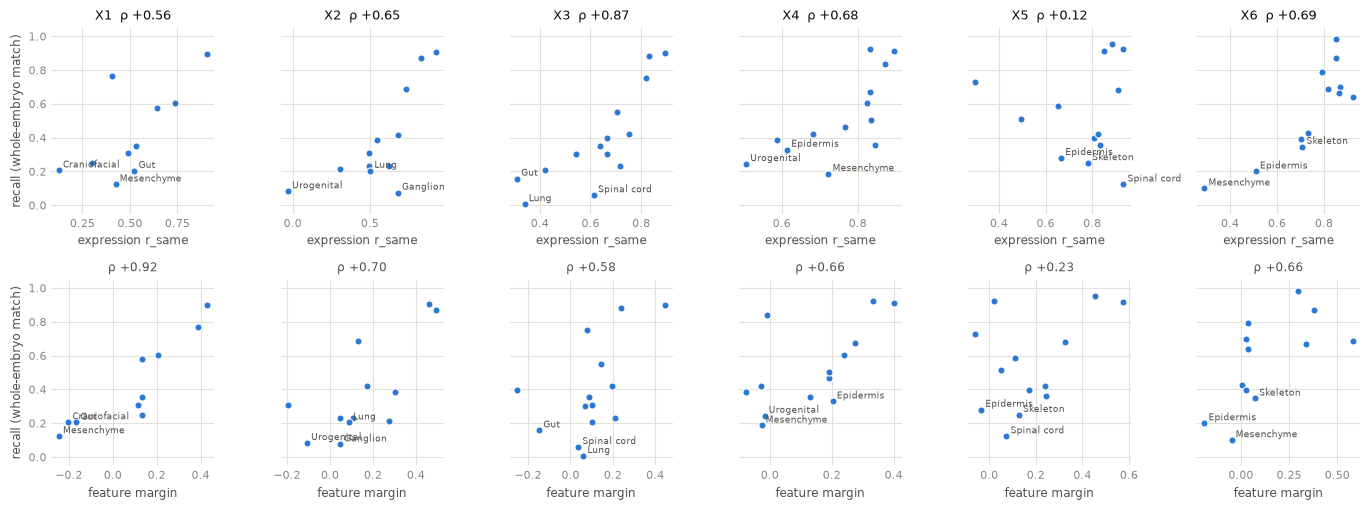

gene r within each organ (its query spots only, >= 20), whole-embryo match, spot-weighted mean
pair            X1    X2    X3    X4    X5    X6
organ                                           
Brain         0.04  0.07  0.27  0.33  0.50  0.41
Skeleton       NaN  0.07  0.13  0.19  0.27  0.24
Mesenchyme    0.04  0.08  0.17  0.21  0.30  0.22
Spinal cord   0.04  0.07  0.23  0.23  0.32  0.34
Muscle         NaN   NaN  0.13  0.15  0.23  0.20
Liver         0.04  0.05  0.09  0.09  0.20  0.09
Heart         0.06  0.07  0.14  0.15  0.19  0.17
Epidermis     0.05  0.07  0.15  0.15  0.16  0.20
Craniofacial  0.04  0.06  0.10  0.18  0.19  0.18
Gut           0.04  0.06  0.09  0.11  0.25  0.20
Urogenital     NaN  0.06  0.11  0.13  0.17   NaN
Ganglion       NaN  0.05  0.17  0.23  0.32  0.31
Lung          0.03  0.07  0.07  0.11  0.12  0.12
Notochord     0.02   NaN   NaN   NaN   NaN   NaN
Ear            NaN   NaN  0.13   NaN  0.12   NaN


In [15]:
fig, axes = plt.subplots(2, len(PAIRS), figsize=(2.3 * len(PAIRS), 5.2), sharey=True, squeeze=False)
for i, (x, xlabel) in enumerate((("same", "expression r_same"), ("f_margin", "feature margin"))):
    for j, pid in enumerate(PAIRS):
        ax = axes[i, j]
        g = cons[cons.pair == pid]
        ax.scatter(g[x], g.recall, s=26, color=SLOT[0], edgecolors=SURFACE, linewidths=0.8)
        for _, r in g.nsmallest(3, "recall").iterrows():
            ax.annotate(r.organ, (r[x], r.recall), fontsize=6.5, color=SECOND, xytext=(3, 2),
                        textcoords="offset points")
        ax.set_ylim(-0.05, 1.05)
        clean(ax)
        if i == 0:
            ax.set_title(f"{pid}  ρ {sp_r(g, x):+.2f}", fontsize=9, color=INK)
        else:
            ax.set_title(f"ρ {sp_r(g, x):+.2f}", fontsize=8.5, color=SECOND)
        ax.set_xlabel(xlabel, fontsize=8.5, color=SECOND)
    axes[i, 0].set_ylabel("recall (whole-embryo match)", fontsize=8.5, color=SECOND)
fig.tight_layout()
plt.show()

g_org = organs[organs.run == REF].dropna(subset=["gene_r"])
g_org = (g_org.assign(w=g_org.n_spots, wr=g_org.gene_r * g_org.n_spots).groupby(["organ", "pair"])[["wr", "w"]].sum())
g_org = (g_org.wr / g_org.w).unstack("pair").reindex(index=order, columns=list(PAIRS)).dropna(how="all")
print(f"gene r within each organ (its query spots only, >= {MIN_SPOTS}), whole-embryo match, spot-weighted mean")
print(g_org.round(2).to_string())

### Stage match

The pairs fix one mouse stage per human stage. If a human embryo's organs resemble a different mouse stage better, the pairing explains part of the difficulty. For every human × mouse embryo of the pairs, the matrix gives the mean r_same over the organs both have, computed as above. It uses the raw log-normalized ortholog counts (`prepare.load_counts`, 1:1 orthologs) and the `N_STAGE_GENES` genes that vary most across the organ profiles, the same genes for every cell.

Each cell averages over the organs its two embryos share, so cells in a row compare different organ sets; `organs` gives their number. The paired cells are outlined.

stage match: mean r_same over shared organs (2000 genes)
            E9.5_E2  E10.5_E1  E11.5_E1  E12.5_E1  E14.5_E1  E13.5_E1
CS12-13_E2    0.434     0.440     0.330     0.361     0.299     0.343
CS14-15_E2    0.365     0.461     0.492     0.474     0.389     0.412
CS17_E1       0.288     0.479     0.581     0.576     0.510     0.556
CS18_E1       0.280     0.463     0.585     0.682     0.643     0.677
CS23_E2       0.228     0.419     0.459     0.599     0.658     0.675
CS20_E2       0.238     0.401     0.495     0.606     0.635     0.662

shared organs
            E9.5_E2  E10.5_E1  E11.5_E1  E12.5_E1  E14.5_E1  E13.5_E1
CS12-13_E2       10        11        13        12        12        11
CS14-15_E2       11        12        14        13        13        12
CS17_E1          11        12        14        13        13        12
CS18_E1          10        12        13        13        13        12
CS23_E2          10        12        14        13        13        12
CS20_E2          1

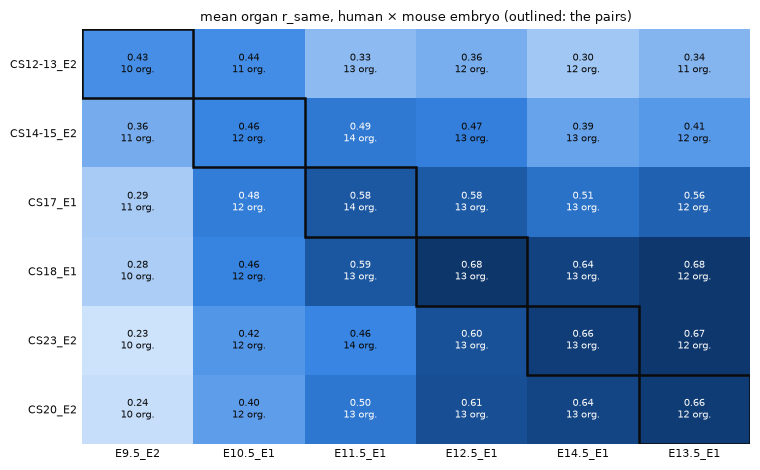

In [16]:
ortho = orthologs.load_one2one()
m2h = dict(zip(ortho.mouse, ortho.human))


def embryo_profiles(emb):
    """Organ profiles (organs x genes, human symbols) of an embryo over all its sections, and spots per organ."""
    pbs, wsum, n = [], 0, 0
    for sec in emb.sections:
        s, a = prepare.load_section(root, sec, seed0, SH), prepare.load_counts(root, sec, seed0, SH)
        W = metrics.row_normalize(s.comp)
        keep_g = a.var_names.isin(set(ortho.human) if emb.dataset == "HESTA" else set(m2h))   # 1:1 orthologs
        X = a.X[:, np.flatnonzero(keep_g)]
        genes = a.var_names[keep_g] if emb.dataset == "HESTA" else a.var_names[keep_g].map(m2h)
        pbs.append(pd.DataFrame(np.asarray((X.T @ W).T), index=list(metrics.ORGANS), columns=genes))
        wsum = wsum + W.sum(0)
        n = n + np.bincount(metrics.organ_codes(s.label), minlength=len(metrics.ORGANS))
    pb = pd.concat(pbs, join="inner").groupby(level=0, sort=False).sum().reindex(list(metrics.ORGANS))
    pb = pb.loc[:, ~pb.columns.str.upper().str.startswith("MT-")]
    return pb.div(np.where(wsum > 0, wsum, 1), axis=0), n


humans = list(dict.fromkeys(ser.pairs[p].a for p in PAIRS))
mice = list(dict.fromkeys(ser.pairs[p].b for p in PAIRS))
prof = {e.name: embryo_profiles(e) for e in humans + mice}
genes = sorted(set.intersection(*(set(prof[e.name][0].columns) for e in humans + mice)))


def var_rank(embs):
    ok = [prof[e.name][0].loc[np.asarray(metrics.ORGANS)[metrics.SCORED & (prof[e.name][1] >= MIN_SPOTS)], genes]
          for e in embs]
    return pd.concat(ok).var().rank(ascending=False)


stage_genes = (0.5 * (var_rank(humans) + var_rank(mice))).nsmallest(N_STAGE_GENES).index
stage, n_org = (pd.DataFrame(index=[e.name for e in humans], columns=[e.name for e in mice], dtype=float)
                for _ in range(2))
for h in humans:
    for m in mice:
        (ph, nh), (pm, nm) = prof[h.name], prof[m.name]
        o = np.flatnonzero(metrics.SCORED & (nh >= MIN_SPOTS) & (nm >= MIN_SPOTS))
        n_org.loc[h.name, m.name] = len(o)
        if len(o) >= 3:
            A, B = (p.iloc[o][stage_genes].to_numpy() for p in (ph, pm))
            stage.loc[h.name, m.name] = np.diag(corr_rows(A - A.mean(0), B - B.mean(0), "pearson")).mean()
print(f"stage match: mean r_same over shared organs ({len(stage_genes)} genes)")
print(stage.round(3).to_string())
print("\nshared organs")
print(n_org.astype(int).to_string())
paired = {(ser.pairs[p].a.name, ser.pairs[p].b.name): p for p in PAIRS}
for h in stage.index:
    best = stage.loc[h].idxmax()
    mine = [m for (hh, m) in paired if hh == h]
    print(f"{h}: best {best} ({stage.loc[h, best]:.3f}); paired {', '.join(f'{m} ({stage.loc[h, m]:.3f}, {paired[(h, m)]})' for m in mine)}")

fig, ax = plt.subplots(figsize=(0.95 * len(mice) + 2, 0.6 * len(humans) + 1.2))
v = stage.to_numpy(dtype=float)
ax.imshow(np.ma.masked_invalid(v), cmap=SEQ, vmin=np.nanmin(v), vmax=np.nanmax(v), aspect="auto")
mid = np.nanmin(v) + 0.55 * (np.nanmax(v) - np.nanmin(v))
for (y, x), val in np.ndenumerate(v):
    if np.isfinite(val):
        ax.text(x, y, f"{val:.2f}\n{int(n_org.iloc[y, x])} org.", ha="center", va="center", fontsize=7,
                color=INK if val < mid else SURFACE)
for (h, m) in paired:
    ax.add_patch(Rectangle((list(stage.columns).index(m) - 0.5, list(stage.index).index(h) - 0.5), 1, 1, fill=False,
                           ec=INK, lw=1.8))
ax.set_xticks(range(len(mice)), stage.columns, fontsize=8, color=INK)
ax.set_yticks(range(len(humans)), stage.index, fontsize=8, color=INK)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("mean organ r_same, human × mouse embryo (outlined: the pairs)", fontsize=9, color=INK)
fig.tight_layout()
plt.show()

## 4. Where space carries information

The GW term's effect per query section: Δκ = κ_bal(`pts2pts_s-euc_f-euc_ub`) − κ_bal(`pts2pts_s-none_f-euc_ub`). The two runs share the points, masses and marginals; only the GW term differs. Next to it, ΔdL and ΔL̄, the change in depth error and in where the mass goes (ΔdL < 0: the GW term moves the mass closer in L).

The position of each query section:
- **inside or beyond:** whether L_q lies inside the L range of the target's sections or beyond its ends (L_rel = (L_q − min L_target) / (max L_target − min L_target) in [0, 1] or not);
- **stack end**: the first or last section of its own stack.

X2 and X3 have the mouse inside the human. Their human queries beyond the mouse range (`b_stack`) and their mouse queries (`a_stack`, which must find their place inside the larger human volume) are the cases where geometry could resolve where in the larger volume a section belongs.

the GW term per query section, by position relative to the target's L range (dk_pos: share with dk > 0)
                                            n     dk  dk_pos    ddL
pair direction     where                                           
X1   human → mouse beyond its ends          4  0.004    1.00 -0.000
                   inside the target range  4  0.004    1.00  0.000
     mouse → human beyond its ends          1  0.007    1.00  0.000
                   inside the target range  3  0.004    1.00  0.000
X2   human → mouse beyond its ends          7  0.021    1.00  0.001
                   inside the target range  3  0.022    1.00  0.000
     mouse → human inside the target range  3  0.026    1.00  0.000
X3   human → mouse beyond its ends          6  0.016    1.00 -0.000
                   inside the target range  4  0.020    1.00  0.000
     mouse → human inside the target range  4  0.016    1.00 -0.000
X4   human → mouse inside the target range  6  0.010    1.00 -0.002
     mouse →

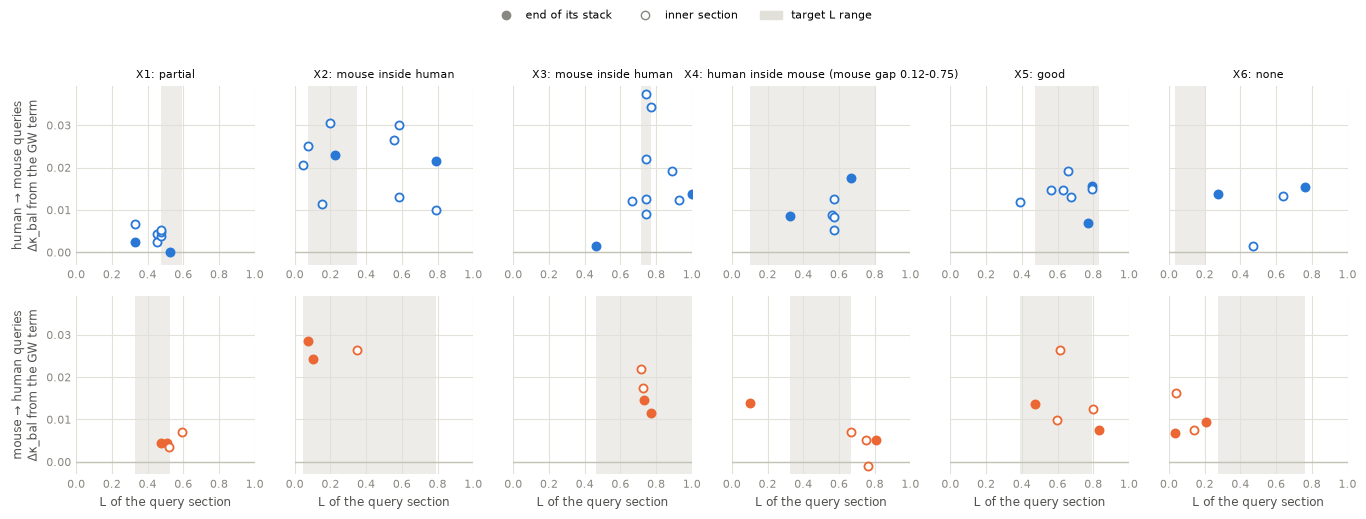

In [17]:
d3 = rows[rows.run.isin([PTS_FGW, PTS_W])].pivot_table(index=KEY[:2] + ["direction", "query"], columns="run",
                                                       values="kappa_bal")
dd = depth[depth.run.isin([PTS_FGW, PTS_W])].pivot_table(index=KEY[:2] + ["direction", "query"], columns="run",
                                                          values=["dL", "L_bar"])
info = rows[rows.run == PTS_FGW].set_index(KEY[:2] + ["direction", "query"])[
    ["L_q", "stack_pos", "stack_n", "t_Lmin", "t_Lmax"]]
gw = info.assign(dk=d3[PTS_FGW] - d3[PTS_W], ddL=dd["dL"][PTS_FGW] - dd["dL"][PTS_W],
                 dLbar=dd["L_bar"][PTS_FGW] - dd["L_bar"][PTS_W]).reset_index()
gw["L_rel"] = (gw.L_q - gw.t_Lmin) / (gw.t_Lmax - gw.t_Lmin).where(gw.t_Lmax > gw.t_Lmin)
gw["inside"] = gw.L_rel.between(0, 1)
gw["stack_end"] = (gw.stack_pos == 0) | (gw.stack_pos == gw.stack_n - 1)
gw["where"] = np.where(gw.inside, "inside the target range", "beyond its ends")

agg = dict(n=("dk", "size"), dk=("dk", "mean"), dk_pos=("dk", lambda x: (x > 0).mean()), ddL=("ddL", "mean"))
print("the GW term per query section, by position relative to the target's L range (dk_pos: share with dk > 0)")
print(gw.assign(direction=gw.direction.map(DIR)).groupby(["pair", "direction", "where"]).agg(**agg).round(3).to_string())
print("\n... and by position in its own stack")
print(gw.assign(direction=gw.direction.map(DIR), end=np.where(gw.stack_end, "stack end", "inner"))
      .groupby(["pair", "direction", "end"]).agg(**agg).round(3).to_string())
grp = np.where(gw.pair.isin(["X2", "X3"]), "X2, X3 (mouse inside human)", "other pairs")
print("\nX2 and X3 against the other pairs")
print(gw.assign(group=grp, direction=gw.direction.map(DIR)).groupby(["group", "direction", "where"]).agg(**agg)
      .round(3).to_string())

# x: the query's own L (L_rel is unbounded for a thin target range, e.g. X3's mouse), the target's L range shaded
fig, axes = plt.subplots(2, len(PAIRS), figsize=(2.3 * len(PAIRS), 5.2), sharey=True, squeeze=False)
for i, d in enumerate(DIR):
    for j, pid in enumerate(PAIRS):
        ax = axes[i, j]
        h = gw[(gw.pair == pid) & (gw.direction == d)]
        if len(h):
            ax.axvspan(h.t_Lmin.iloc[0], h.t_Lmax.iloc[0], color=GRID, alpha=0.6, lw=0)
        ax.axhline(0, color=BASE, lw=1)
        for end, face in ((True, SLOT[i]), (False, SURFACE)):
            hh = h[h.stack_end == end]
            ax.scatter(hh.L_q, hh.dk, s=34, facecolors=face, edgecolors=SLOT[i], linewidths=1.3, zorder=3)
        ax.set_xlim(0, 1)
        clean(ax)
        if i == 0:
            ax.set_title(f"{pid}: {ser.pairs[pid].overlap}", fontsize=8, color=INK)
        else:
            ax.set_xlabel("L of the query section", fontsize=8.5, color=SECOND)
        if j == 0:
            ax.set_ylabel(f"{DIR[d]} queries\nΔκ_bal from the GW term", fontsize=8.5, color=SECOND)
handles = [Line2D([], [], marker="o", ls="", color=MUTED, label="end of its stack"),
           Line2D([], [], marker="o", ls="", mfc=SURFACE, mec=MUTED, label="inner section"),
           Patch(color=GRID, label="target L range")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))
plt.show()

### Figure: the GW gain on the slices

For `SLICE_PAIRS`, one panel per query section, both directions, ordered by L. Each spot is coloured by what the GW term changes in its transferred organ (arg-max of its row of the coupling, against its majority label):
- **gained:** right with the GW term, wrong without;
- **lost:** wrong with the GW term, right without;
- right in both, wrong in both;
- not scored (Other, Excluded), drawn faint.

Under each slice, the share of its mass on each target section, along the target's L, with and without the GW term; the vertical line marks the query's own L.

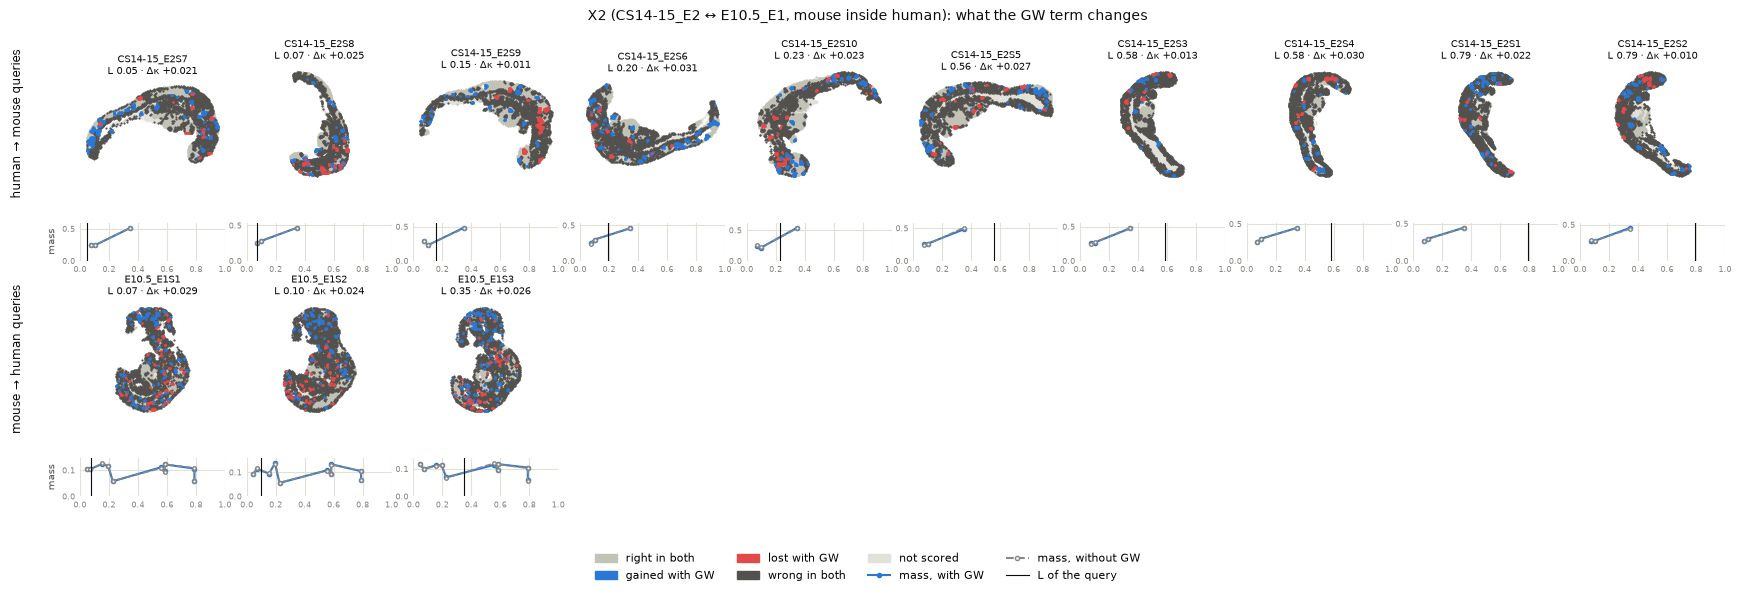

X2: share of the scored spots gained and lost with the GW term
    direction         query  gained  lost    dk
human → mouse  CS14-15_E2S7   0.059 0.010 0.021
human → mouse  CS14-15_E2S8   0.032 0.021 0.025
human → mouse  CS14-15_E2S9   0.029 0.030 0.011
human → mouse  CS14-15_E2S6   0.054 0.010 0.031
human → mouse CS14-15_E2S10   0.049 0.023 0.023
human → mouse  CS14-15_E2S5   0.043 0.018 0.027
human → mouse  CS14-15_E2S3   0.024 0.011 0.013
human → mouse  CS14-15_E2S4   0.022 0.019 0.030
human → mouse  CS14-15_E2S1   0.035 0.008 0.022
human → mouse  CS14-15_E2S2   0.038 0.021 0.010
mouse → human    E10.5_E1S1   0.042 0.020 0.029
mouse → human    E10.5_E1S2   0.034 0.021 0.024
mouse → human    E10.5_E1S3   0.041 0.017 0.026


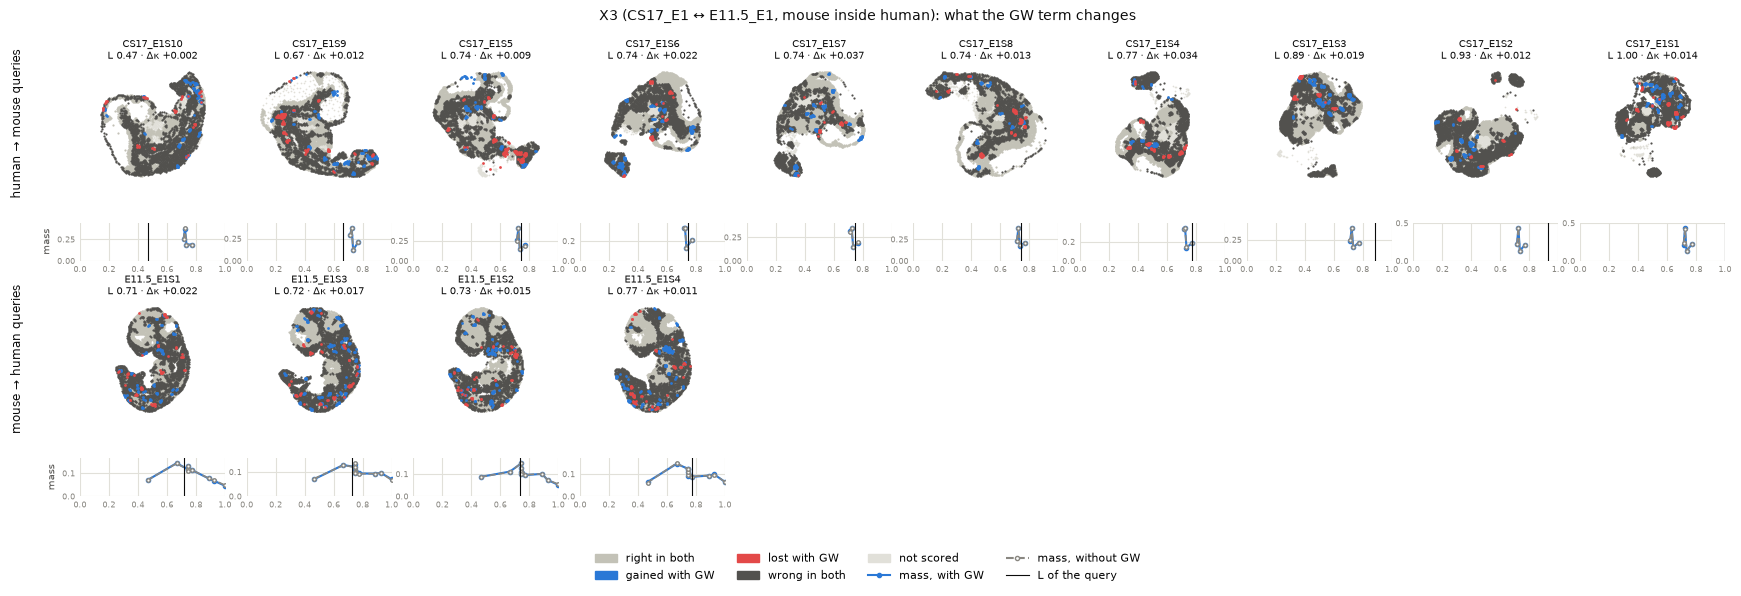

X3: share of the scored spots gained and lost with the GW term
    direction      query  gained  lost    dk
human → mouse CS17_E1S10   0.023 0.009 0.002
human → mouse  CS17_E1S9   0.027 0.019 0.012
human → mouse  CS17_E1S5   0.021 0.023 0.009
human → mouse  CS17_E1S6   0.028 0.008 0.022
human → mouse  CS17_E1S7   0.025 0.006 0.037
human → mouse  CS17_E1S8   0.014 0.014 0.013
human → mouse  CS17_E1S4   0.015 0.017 0.034
human → mouse  CS17_E1S3   0.026 0.010 0.019
human → mouse  CS17_E1S2   0.018 0.006 0.012
human → mouse  CS17_E1S1   0.026 0.016 0.014
mouse → human E11.5_E1S1   0.017 0.011 0.022
mouse → human E11.5_E1S3   0.031 0.012 0.017
mouse → human E11.5_E1S2   0.025 0.012 0.015
mouse → human E11.5_E1S4   0.027 0.012 0.011


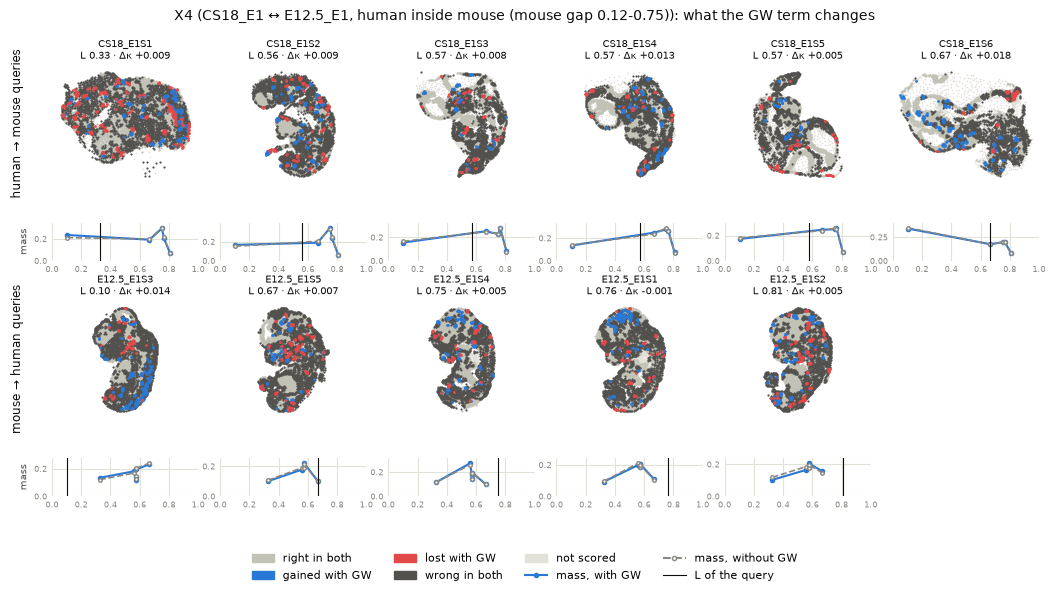

X4: share of the scored spots gained and lost with the GW term
    direction      query  gained  lost     dk
human → mouse  CS18_E1S1   0.038 0.054  0.009
human → mouse  CS18_E1S2   0.034 0.024  0.009
human → mouse  CS18_E1S3   0.016 0.016  0.008
human → mouse  CS18_E1S4   0.032 0.015  0.013
human → mouse  CS18_E1S5   0.014 0.017  0.005
human → mouse  CS18_E1S6   0.049 0.016  0.018
mouse → human E12.5_E1S3   0.041 0.012  0.014
mouse → human E12.5_E1S5   0.021 0.029  0.007
mouse → human E12.5_E1S4   0.030 0.017  0.005
mouse → human E12.5_E1S1   0.034 0.017 -0.001
mouse → human E12.5_E1S2   0.030 0.029  0.005


In [18]:
CAT = {"right in both": BASE, "gained with GW": "#2a78d6", "lost with GW": "#e34948", "wrong in both": SECOND}
for pid in [p for p in SLICE_PAIRS if p in PAIRS]:
    transfer = np.load(files(pid, seed0)["transfer"])
    pair = ser.pairs[pid]
    secs = {s: prepare.load_section(root, s, seed0, SH) for e in pair.embryos for s in e.sections}
    queries = {d: sorted([q for q in (pair.a if d == "b_stack" else pair.b).sections],
                         key=lambda s: (np.nan_to_num(secs[s].L, nan=9), s)) for d in DIR}
    ncol = max(len(v) for v in queries.values())
    fig = plt.figure(figsize=(max(1.75 * ncol, 8), 2 * 2.65 + 0.5))
    gs = fig.add_gridspec(4, ncol, height_ratios=[3, 1, 3, 1], hspace=0.55, wspace=0.15, top=0.88, bottom=0.14,
                          left=0.05, right=0.99)
    counts = []
    for i, d in enumerate(DIR):
        mt = mass[(mass.pair == pid) & (mass.seed == seed0) & (mass.direction == d)]
        for j, qn in enumerate(queries[d]):
            q = secs[qn]
            lab = metrics.organ_codes(q.label)
            scored = metrics.SCORED[lab]
            a, b = transfer[f"{PTS_FGW}|{d}|{qn}"] == lab, transfer[f"{PTS_W}|{d}|{qn}"] == lab
            cat = np.select([a & b, a & ~b, ~a & b], list(CAT)[:3], list(CAT)[3])
            ax = fig.add_subplot(gs[2 * i, j])
            ax.scatter(*q.xy[~scored].T, s=1.5, color=GRID, linewidths=0, rasterized=True)
            for c, color in CAT.items():
                m = scored & (cat == c)
                ax.scatter(*q.xy[m].T, s=2.5 if c in ("right in both", "wrong in both") else 4, color=color,
                           linewidths=0, rasterized=True, zorder=3 if "with GW" in c else 2)
            r = gw[(gw.pair == pid) & (gw.seed == seed0) & (gw.direction == d) & (gw["query"] == qn)]
            dk = r.dk.iloc[0] if len(r) else np.nan
            ax.set_title(f"{qn}\nL {q.L:.2f} · Δκ {dk:+.3f}", fontsize=7, color=INK)
            ax.set_aspect("equal")
            ax.invert_yaxis()
            ax.axis("off")
            counts.append(dict(direction=DIR[d], query=qn, gained=(scored & (cat == "gained with GW")).mean() / scored.mean(),
                               lost=(scored & (cat == "lost with GW")).mean() / scored.mean(), dk=dk))
            # the mass per target section, along the target's L
            sx = fig.add_subplot(gs[2 * i + 1, j])
            top = 0.05
            for run, style in ((PTS_FGW, dict(color=CAT["gained with GW"], lw=1.5, marker="o", ms=3)),
                               (PTS_W, dict(color=MUTED, lw=1.2, ls="--", marker="o", ms=2.5, mfc=SURFACE))):
                h = mt[(mt.run == run) & (mt["query"] == qn)].dropna(subset=["L_t"]).sort_values("L_t")
                sx.plot(h.L_t, h.share, **style)
                top = max(top, h.share.max() if len(h) else 0)
            sx.axvline(q.L, color=INK, lw=0.8)
            sx.set(xlim=(0, 1), ylim=(0, 1.15 * top))
            clean(sx)
            sx.tick_params(labelsize=6)
            if j == 0:
                sx.set_ylabel("mass", fontsize=7, color=SECOND)
        bb = gs[2 * i, 0].get_position(fig)
        fig.text(0.01, (bb.y0 + bb.y1) / 2, f"{DIR[d]} queries", rotation=90, ha="left", va="center", fontsize=8.5,
                 color=INK)
    handles = [Patch(color=c, label=k) for k, c in CAT.items()] + [Patch(color=GRID, label="not scored")]
    handles += [Line2D([], [], color=CAT["gained with GW"], marker="o", ms=3, label="mass, with GW"),
                Line2D([], [], color=MUTED, ls="--", marker="o", ms=3, mfc=SURFACE, label="mass, without GW"),
                Line2D([], [], color=INK, lw=0.8, label="L of the query")]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.06), ncol=4, frameon=False, fontsize=8)
    fig.suptitle(f"{pid} ({pair.a.name} ↔ {pair.b.name}, {pair.overlap}): what the GW term changes", y=0.98,
                 fontsize=10, color=INK)
    plt.show()
    print(f"{pid}: share of the scored spots gained and lost with the GW term")
    print(pd.DataFrame(counts).round(3).to_string(index=False))

## How to read the results

**Depth (sections 1 and 2)**
- **Depth skill near 0 and ρ near 0 for the feature runs:** the features don't place sections in depth; κ_bal's gains come from organ identity alone. If 3D FGW has a clearly higher skill or ρ than the whole-embryo match, the GW term carries depth information that κ_bal does not reward.
- **The label ceiling.** If its skill is high, organ content does follow L across species, and a depth score in L is meaningful. If it is near 0 too, either L is not comparable between the species or organs alone don't fix depth. Then the composition-against-ΔL check decides between the two: ρ < 0 there means L is comparable.
- **X8:** a share on the end section well above chance means the method sends sections to the closest depth it can, as it should with no overlap.
- **Next step:** the depth skill, or ρ if L turns out comparable only in order, becomes the score next to κ_bal for the "space as an addition" tests in the doc.

**The hard pairs (section 3)**
- **Lower conservation on X1 and X2, with recall that follows it:** the biology is harder (the early organs are less alike, or less separable in expression), and better features can only help so much.
- **Similar conservation but lower recall, or a low f_margin where the expression margin is fine:** the shared embedding loses what the genes still hold. Integration across species (Harmony, scVI) or other gene sets is the lever.
- **Stage match:** if a human embryo's best mouse embryo is not its pair, the stage pairing explains part of the difficulty. Note that each cell averages over a different set of organs.

**Space (section 4)**
- **Δκ > 0 mainly beyond the ends of the target range, or on mouse queries of X2 and X3:** the geometry helps to place a section within the larger volume. ΔdL < 0 for the same sections confirms it with depth.
- **Δκ spread evenly over positions:** the GW term acts as a general regularizer of the coupling (smoother, more spatially coherent transfers), not as a depth cue. The slices show which: gained spots in compact regions (a whole organ moved) or scattered (local smoothing).